# 2. Build flow maps from CSV files

The same inputs you upload on FlowMapper.org (nodes, flows, region polygons and a region attribute
table) can be turned into a project with `fm.Project.from_data`.

Data: refugees from Ukraine by country of asylum (UNHCR) and county-to-county migration around
Hurricane Katrina (IRS), from the FlowMapper repository.

### Setup

Imports, the data folder, and a few helpers used below: `figure_ground()` (the high-contrast look),
`size_nodes_by_total_flow()`, `show()` / `map_image()` / `show_grid()` (draw maps) and
`compare_settings()` (draw the same map with different settings side by side).

In [1]:
%matplotlib inline
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowmapper_org as fm

# Example data of the FlowMapper GitHub repository (folder "Data"): FLOWMAPPER_DATA, else the
# repository these notebooks live in (python/notebooks -> ../../Data), else a local clone.
_candidates = [os.environ.get("FLOWMAPPER_DATA"), Path.cwd().parent.parent / "Data", r"D:\GitHub\flowmapper\Data"]
DATA = next((Path(c) for c in _candidates if c and Path(c).is_dir()), None)
assert DATA is not None, ("FlowMapper example data not found: clone https://github.com/geo-social/flowmapper "
                          "and set FLOWMAPPER_DATA to its Data folder")
OUT = Path("output")
OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("flowmapper.org", fm.__version__, "- mirrors FlowMapper.org", fm.FLOWMAPPER_WEB_VERSION)

# ---------------------------------------------------------------------------------------------
# The look used in these notebooks: figure-ground contrast.
#   * flows are the figure: Tapered Fading Arc (TAF), dark colour ramps, full opacity;
#   * regions are the ground: their colours are kept but drawn pale (35 % opacity);
#   * nodes are drawn on top of the flows, dark grey with a white outline.
# figure_ground() only sets ordinary FlowMapper settings, so the projects still open on
# FlowMapper.org. CONTRAST holds two Python-only drawing options (never saved in the file):
#   flow_contrast - raises the opacity of the fading arcs, so small flows stay visible;
#   flow_halo     - a thin white casing that separates flows from the regions below.
# ---------------------------------------------------------------------------------------------
CONTRAST = dict(flow_contrast=0.5, flow_halo=("#ffffff", 0.7))

# Zoom extents (west, south, east, north), a drawing option: render(..., extent=...).
# The legend and title are kept outside the extent.
LOWER48 = (-125, 24, -66.5, 49.5)
EUROPE = (-12, 34, 58, 68)


def us_extent(p):
    """LOWER48 when most of the project's nodes are in the contiguous U.S., else None.

    Every U.S. map in these notebooks is zoomed to the lower 48 (not Alaska and Hawaii):
    map_image() / show() use this whenever no extent is given."""
    ns = p.node_settings
    xf, yf = ns.get("X"), ns.get("Y")
    if p.nodes is None or xf not in p.nodes.columns or yf not in p.nodes.columns:
        return None
    x = pd.to_numeric(p.nodes[xf], errors="coerce")
    y = pd.to_numeric(p.nodes[yf], errors="coerce")
    ok = x.notna() & y.notna()
    if not ok.any():
        return None
    w, s, e, n = LOWER48
    inside = (x[ok].between(w, e) & y[ok].between(s, n)).mean()
    return LOWER48 if inside >= 0.8 else None

# Dark ramps (light end, dark end). The light end is a mid-tone, so the smallest flows
# are still clearly visible; a ColorBrewer ramp such as "Blues" starts almost white.
FLOW_RAMPS = {
    "navy":   ("#4a6fa5", "#0b1f4b"),
    "orange": ("#f16913", "#7f2704"),
    "purple": ("#807dba", "#3f007d"),
    "teal":   ("#3a9e8f", "#00332b"),
}


def figure_ground(p, flows="navy", region_opacity=35, node_color="#3d3d3d"):
    """Pale regions, dark prominent flows, nodes on top (ordinary FlowMapper settings)."""
    lo, hi = FLOW_RAMPS[flows] if flows in FLOW_RAMPS else flows
    p.flow_settings.update(flowStyleName="TAF", clrScheme="Custom", minCustomColor=lo, maxCustomColor=hi,
                           fillOpacity=100)
    p.region_settings.update(fillOpacity=region_opacity, strokeColor="#9e9e9e", strokeWidth=0.4)
    p.node_settings.update(clrScheme="Custom", minCustomColor=node_color, maxCustomColor=node_color,
                           noAttrFillColor=node_color, strokeColor="#ffffff", strokeWidth=0.8, fillOpacity=100)
    p.view_settings["drawingOrder"] = "nodes"          # nodes on top of flows
    return p


def size_nodes_by_total_flow(p, rmin=2, rmax=16, title="Total flow (in + out)", measure="__fm:grossflow"):
    """Circle size = gross flow (in-flow + out-flow), calculated from the flows.

    measure="__fm:inflow" sizes by flow received instead: better when one origin sends
    everything (refugees from one country), where the origin's total would dwarf the rest."""
    p.node_settings.update(ifMapAttribute=True, volume=measure, cfMethod="Proportional",
                           radiusMin=rmin, radiusMax=rmax, legendTitle=title)
    return p


_seen_notices = set()


def map_image(project, contrast=True, **render_options):
    """Draw a project at its own size and return the picture as an array.

    contrast=True adds the CONTRAST drawing options; False draws exactly as FlowMapper.org.
    Legends, title and scale bar are sized in screen pixels, so maps are drawn on their own
    and then tiled, rather than squeezed into small subplot axes."""
    opts = {**(CONTRAST if contrast else {}), **render_options}
    if "extent" not in opts and us_extent(project) is not None:
        opts["extent"] = LOWER48         # U.S. data: the lower 48, never Alaska and Hawaii
    r = project.render(**opts)       # with an extent, the title and legend are kept off the extent
    for n in r.notices:                     # FlowMapper's messages, each shown once
        if n not in _seen_notices:
            _seen_notices.add(n)
            print("notice:", n)
    buf = io.BytesIO()
    r.fig.savefig(buf, format="png")
    buf.seek(0)
    return plt.imread(buf)


def show(project, width=1000, height=700, contrast=True, **render_options):
    """Draw one map in the notebook."""
    show_grid([map_image(project, contrast, width=width, height=height, **render_options)], ncols=1,
              width=width / 70)


def show_grid(images, titles=None, ncols=3, width=22):
    """Tile pictures (arrays from map_image or plt.imread) in a grid."""
    nrows = -(-len(images) // ncols)
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, width / ncols * h / w * nrows + 0.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, t in zip(axes.flat, images, titles or [""] * len(images)):
        ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()


def compare_settings(base, variants, ncols=3, width=900, height=600, **render_options):
    """Draw copies of `base`, each with some settings changed.

    variants = {"label": {"flow_settings": {...}, "node_settings": {...}, ...}, ...}"""
    images = []
    for label, change in variants.items():
        q = base.copy()
        for block, values in change.items():
            getattr(q, block).update(values)
        images.append(map_image(q, width=width, height=height, **render_options))
    show_grid(images, list(variants), ncols=ncols)

flowmapper.org 0.3.0 - mirrors FlowMapper.org 2.1


## Ukraine refugees, 2022

In [2]:
U = DATA / "Refugees" / "Ukraine"
display(pd.read_csv(U / "flows_ukraine_refugees_2022.csv").head())
display(pd.read_csv(U / "nodes_countries.csv").head(3))

,origin,destination,destination_name,refugees,asylum_seekers
0,UKR,RUS,Russian Federation,1275315,610
1,UKR,DEU,Germany,1002999,1383
2,UKR,POL,Poland,958147,372
3,UKR,CZE,Czechia,433501,137
4,UKR,GBR,United Kingdom of Great Britain and Northern I...,182423,976


,iso3,country,continent,subregion,lon,lat,population_2024,gdp_per_capita_usd_2024,gdp_billion_usd_2024,migrant_stock_pct_2024,refugees_2022,refugees_2023,refugees_2024,refugees_per_1000_pop_2024,share_of_all_ukr_refugees_pct_2024
0,ZWE,Zimbabwe,Africa,Eastern Africa,29.9254,-18.9116,16634373.0,2496.0,41.5,2.6,NaN,NaN,NaN,NaN,NaN
1,ZMB,Zambia,Africa,Eastern Africa,26.3953,-14.6608,21314956.0,1187.0,25.3,1.2,NaN,NaN,NaN,NaN,NaN
2,YEM,Yemen,Asia,Western Asia,45.8744,15.3282,40583164.0,634.0,21.6,1.0,NaN,NaN,NaN,NaN,NaN


In [3]:
p = fm.Project.from_data(
    U / "nodes_countries.csv", U / "flows_ukraine_refugees_2022.csv",
    regions=U / "regions_europe.geojson",
    region_table=U / "nodes_countries.csv",
    volume="refugees",                 # the flow file has two numeric fields; choose one
    name="Ukraine refugees 2022 (built in Python)")
print(p)
print("node fields :", {k: p.node_settings[k] for k in ("id", "X", "Y")})
print("flow fields :", {k: p.flow_settings[k] for k in ("origin", "destination", "volume")})
print("projection  :", p.basemap_settings["projection"])

<Project 'Ukraine refugees 2022 (built in Python)': 65 regions, 240 nodes, 64 flows>
node fields : {'id': 'iso3', 'X': 'lon', 'Y': 'lat'}
flow fields : {'origin': 'origin', 'destination': 'destination', 'volume': 'refugees'}
projection  : webMct


FlowMapper.org's defaults: Tapered Fading Arcs, proportional widths, top 100 flows, no region
colours, unsized nodes.

notice: The flow file has 64 flows between two different nodes, so "Show top flows" was set to 64.


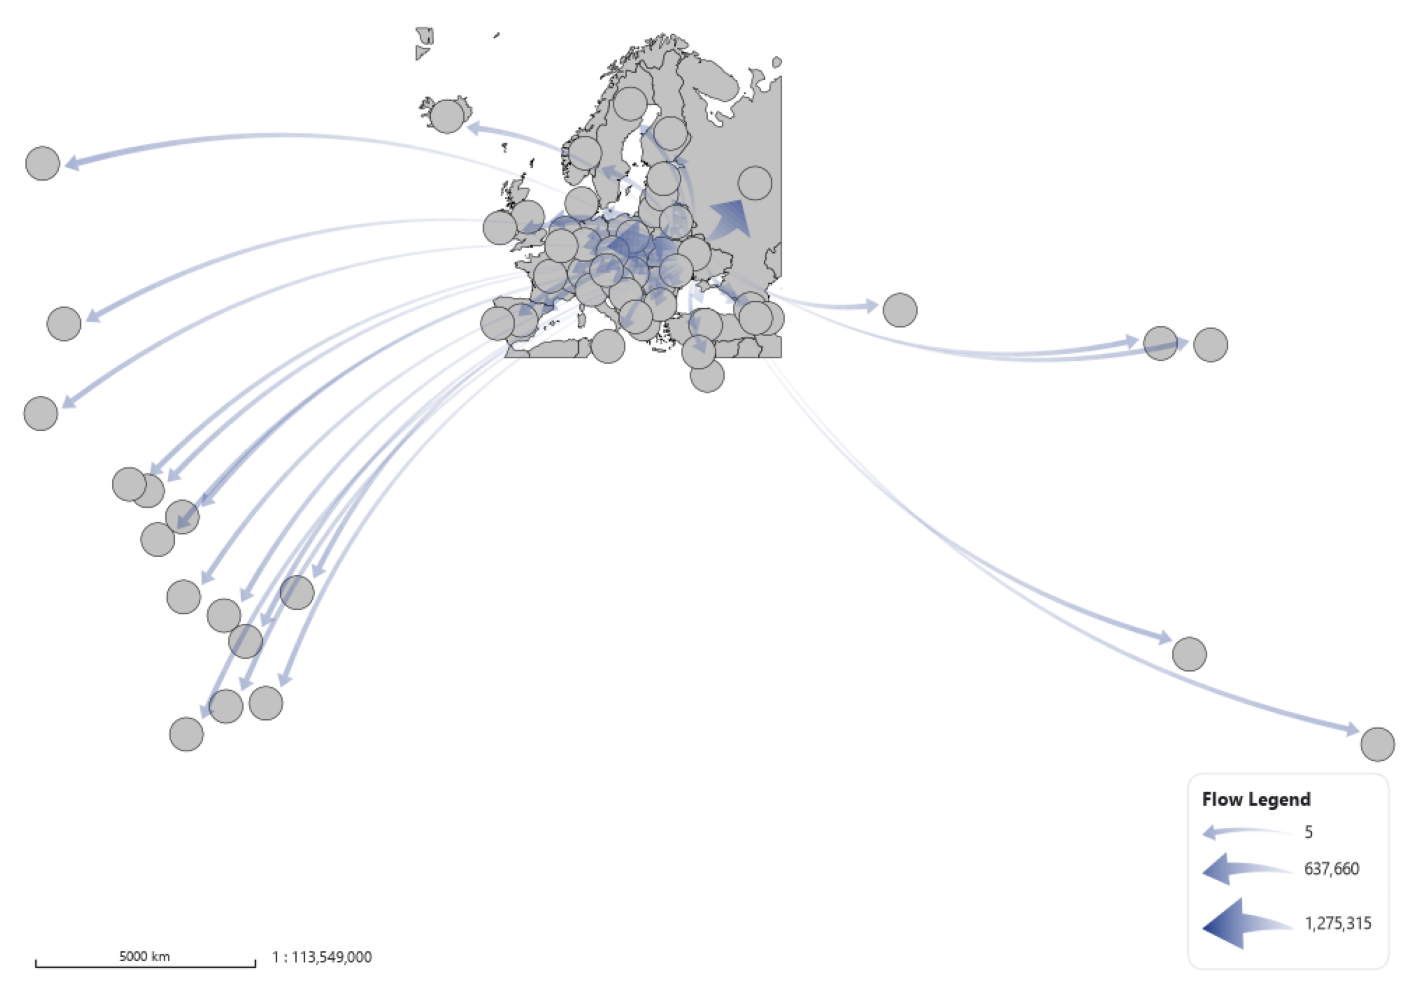

In [4]:
show(p, contrast=False)

### Style it step by step

**Regions**: join GDP per capita to the polygons (`geoId` = polygon property, `CSVId` = table
column, `value` = column to map) and draw them pale (`fillOpacity` 35).

In [5]:
print("polygon properties:", list(p.regions["features"][0]["properties"]))
b, rs, rj, ns, fs = p.basemap_settings, p.region_settings, p.region_join, p.node_settings, p.flow_settings

b.update(projection="laeaEurope", ifAddTitle=True, title="Refugees from Ukraine, 2022", titleSize=22)
rj.update(geoId="iso3", CSVId="iso3", value="gdp_per_capita_usd_2024")
rs.update(ifMapRegionAttribute=True, attrSource="csv", cfMethod="Quantile", clsNum=5, clrScheme="Greens",
          legendTitle="GDP per capita (USD), 2024")

polygon properties: ['iso3', 'name', '__fm_id']


**Flows**: Tapered Fading Arc, natural breaks, a dark navy ramp, the 40 largest flows.
**Nodes**: sized by in-flow (refugees received), calculated from the flows.
`figure_ground()` sets the opacity, outlines and drawing order.

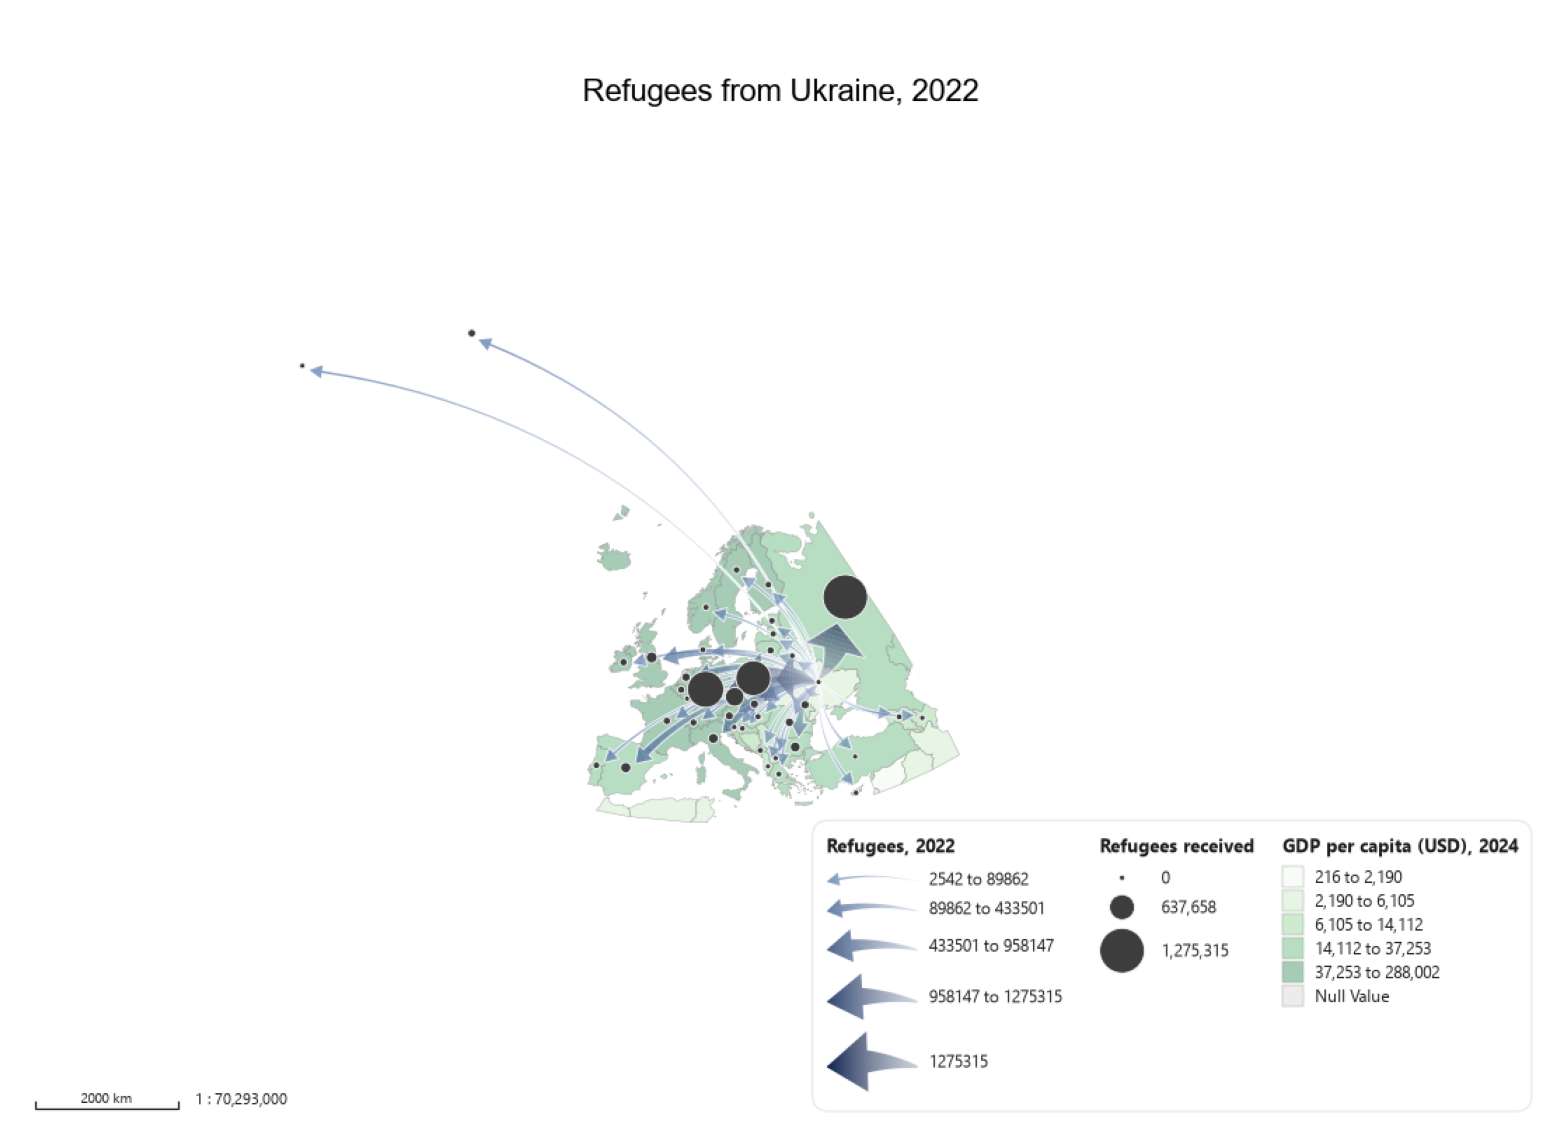

In [6]:
fs.update(flowStyleName="TAF", cfMethod="NaturalBreak", clsNum=5, numTopFlows=40, widthMin=1.5, widthMax=16,
          legendTitle="Refugees, 2022")
figure_ground(p, flows="navy")
ns.update(ifMapAttribute=True, volume="__fm:inflow", cfMethod="Proportional", radiusMin=2, radiusMax=16,
          legendTitle="Refugees received")
show(p, width=1100, height=800)

The two flows to North America stretch the map. `extent=(west, south, east, north)` zooms to
Europe for the picture (those two flows then leave the frame). `EUROPE` is defined in the setup
cell; the legend and title are kept outside the extent.

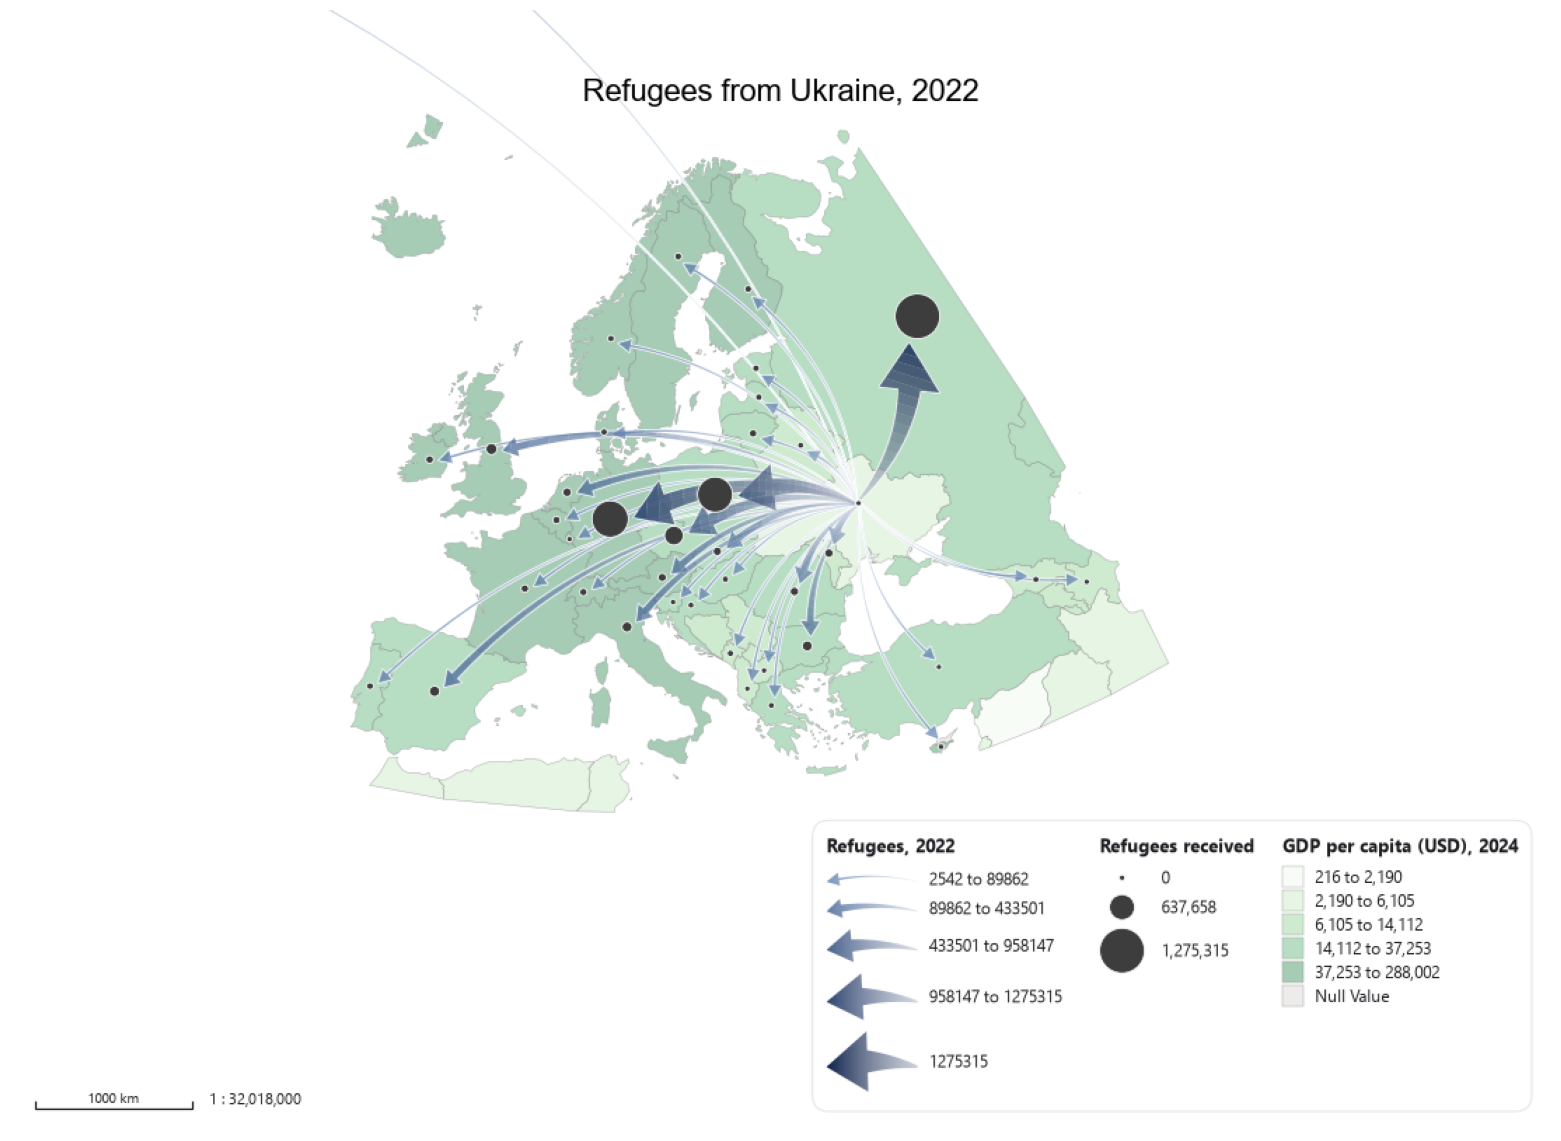

In [7]:
show(p, width=1100, height=800, extent=EUROPE)

Try it: change `numTopFlows`, `clrScheme`, `region_settings["fillOpacity"]` or the flow ramp
(`figure_ground(p, flows="orange")`) above and run the cells again.

In [8]:
p.save(OUT / "ukraine_2022_python.json")       # open on FlowMapper.org: File > Project > Load Project
p.save_map(OUT / "ukraine_2022_python.png", width=1100, height=800, dpi=144, **CONTRAST)

WindowsPath('output/ukraine_2022_python.png')

### Compare years

The project is copied for each year and only the flow table changes. Manual breaks keep the
classes the same in every year.

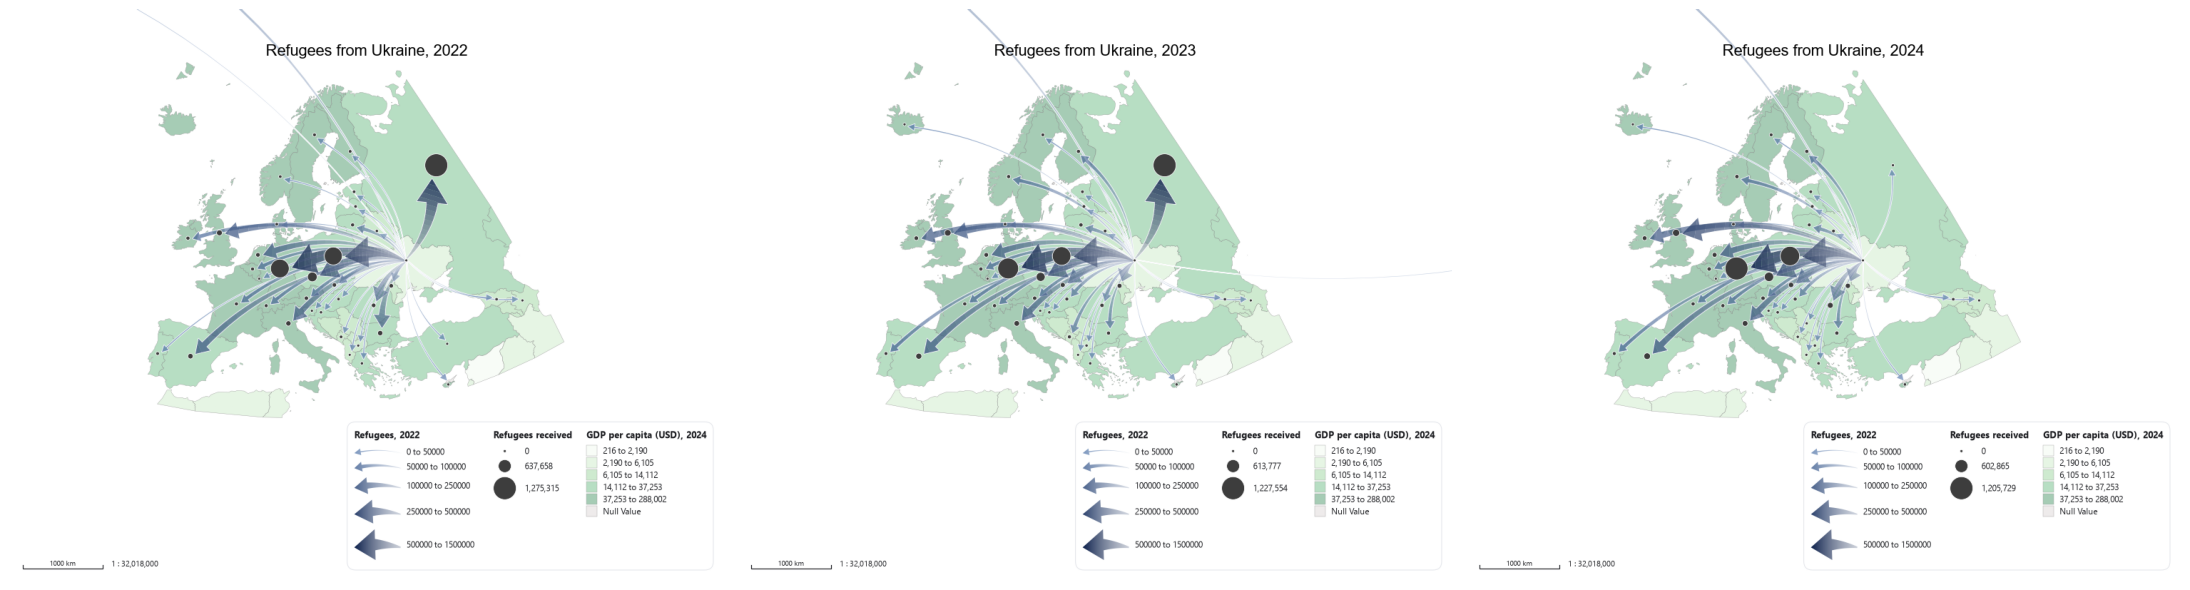

In [9]:
images = []
for year in (2022, 2023, 2024):
    q = p.copy()
    q.flows = fm.read_csv(U / f"flows_ukraine_refugees_{year}.csv")
    q.basemap_settings["title"] = f"Refugees from Ukraine, {year}"
    q.flow_settings.update(cfMethod="ManualBreak", breakInput="0 50000 100000 250000 500000 1500000")
    images.append(map_image(q, width=1000, height=800, extent=EUROPE))
show_grid(images, ncols=3)

## Hurricane Katrina: county-to-county migration, four periods

Flows out of the affected counties in each IRS year. States are shaded (pale) by the persons
they received, and county nodes are sized by total flow.

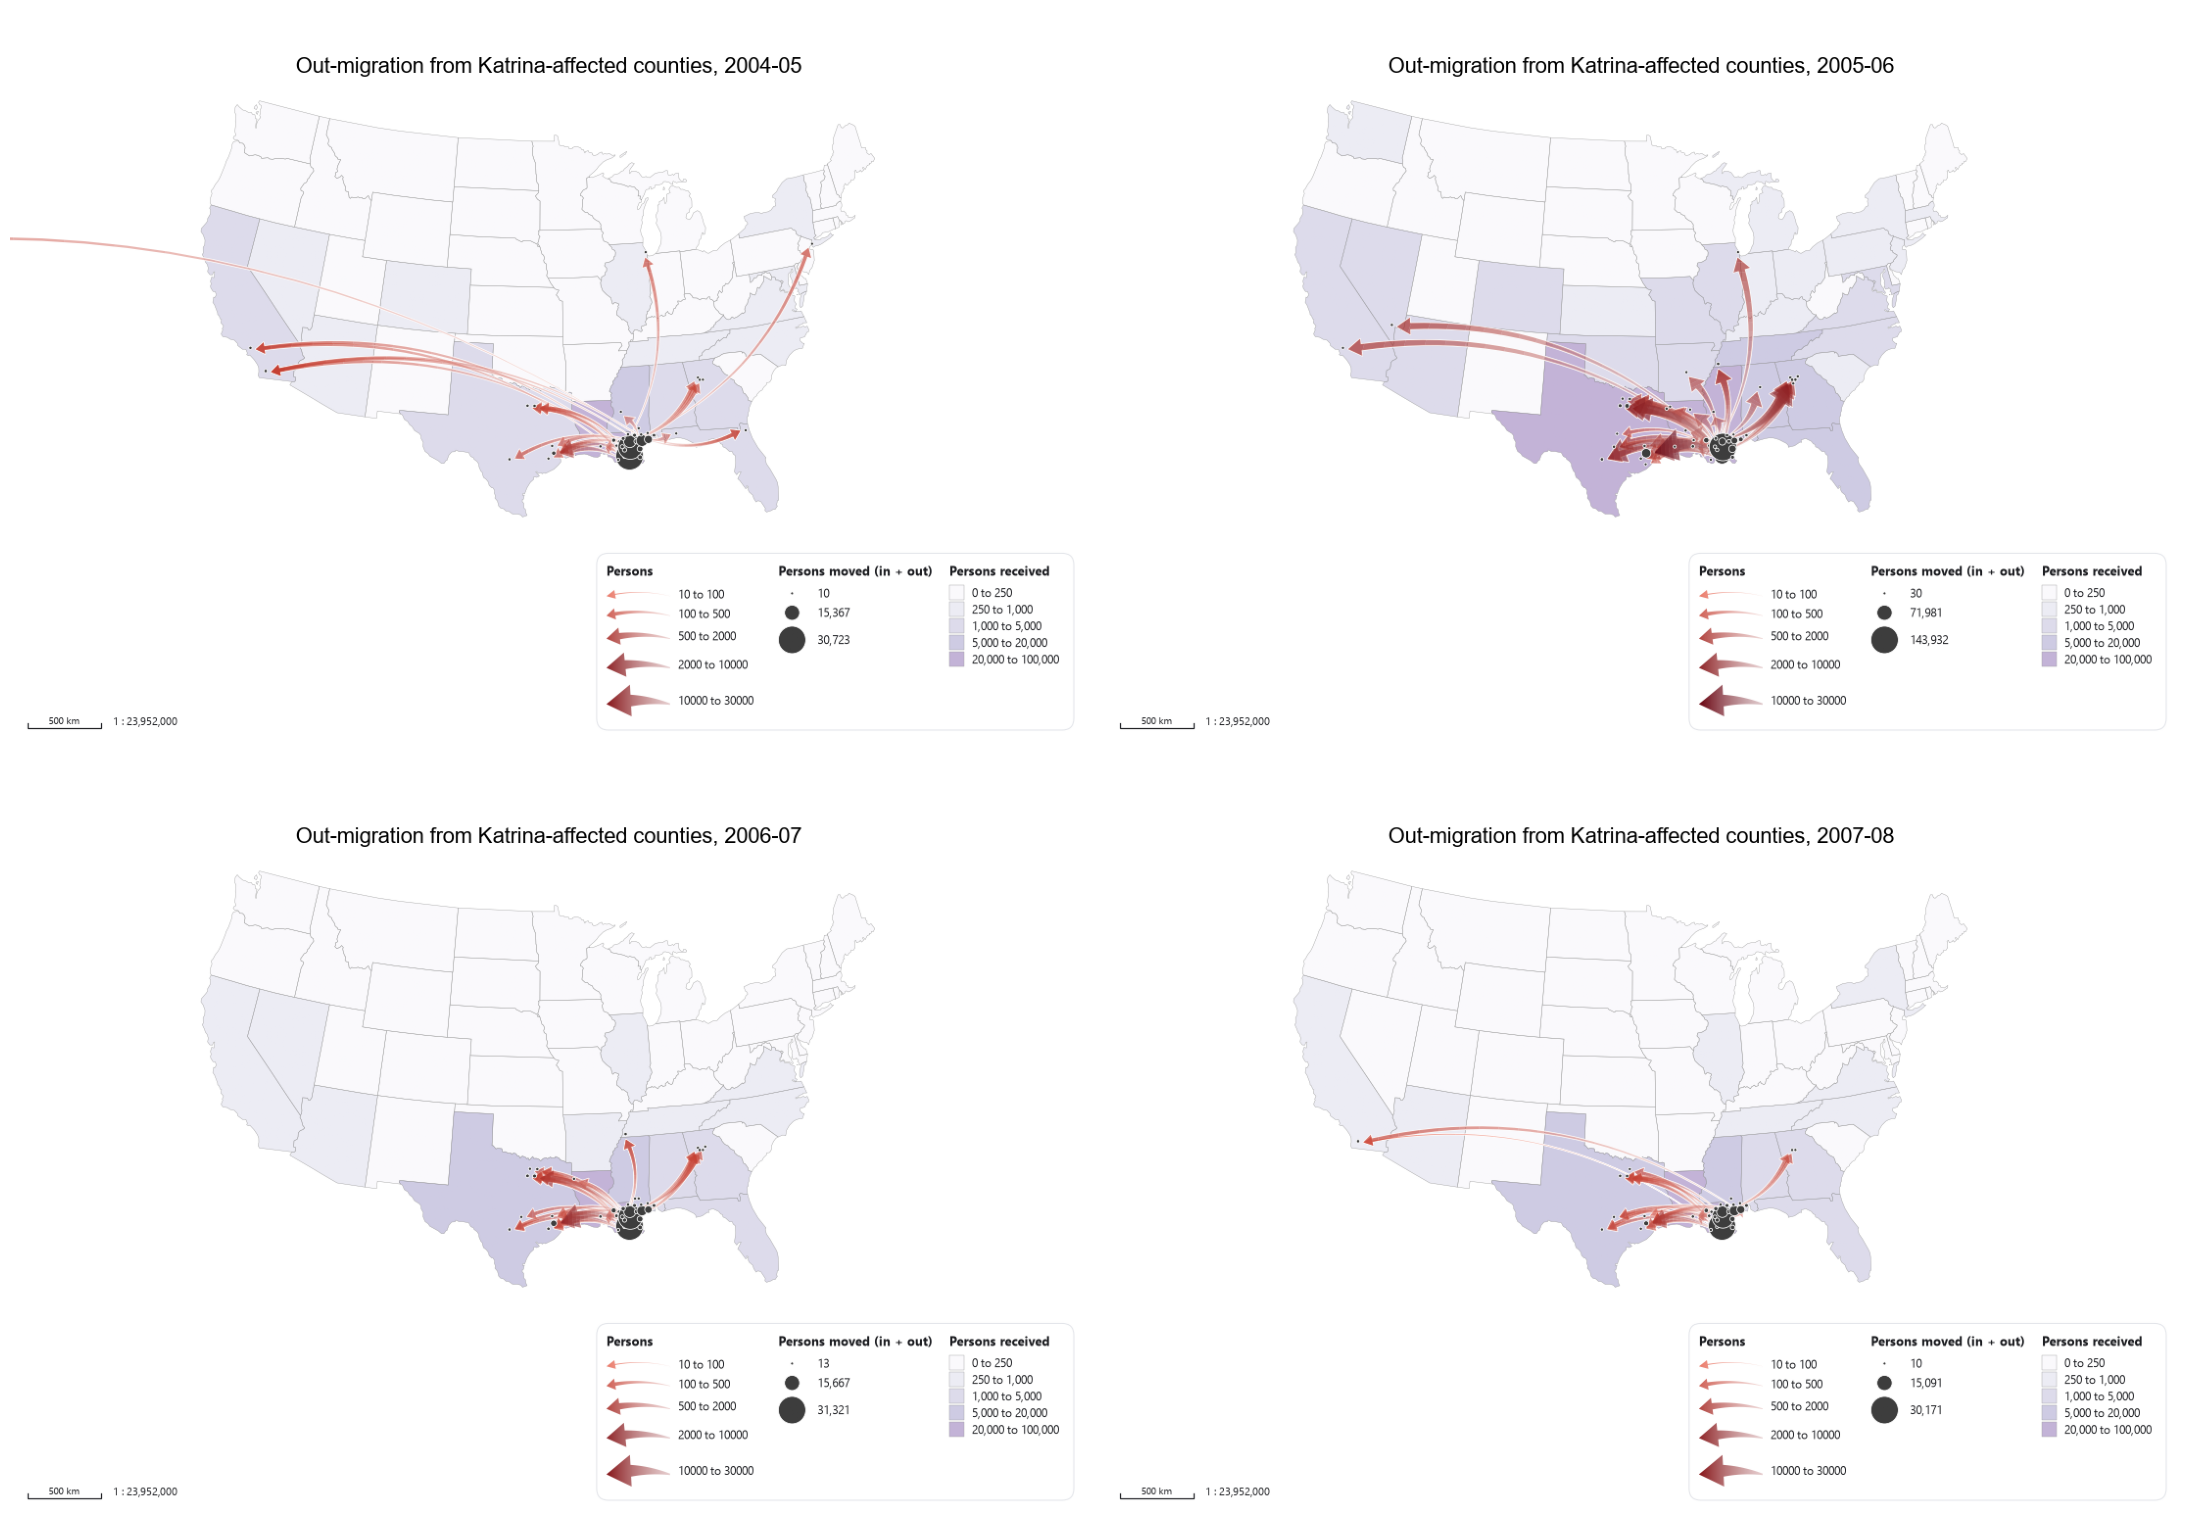

In [10]:
K = DATA / "DisasterMigration" / "Katrina"
kat = fm.Project.from_data(K / "nodes_counties.csv", K / "flows_katrina_out_2005_06.csv",
                           regions=K / "regions_us_states.geojson",
                           region_table=K / "regions_states_katrina_totals.csv", volume="persons")
kat.region_join.update(geoId="name", CSVId="name")
kat.region_settings.update(ifMapRegionAttribute=True, cfMethod="ManualBreak", clrScheme="Purples",
                           breakInput="0 250 1000 5000 20000 100000", legendTitle="Persons received")
kat.flow_settings.update(cfMethod="ManualBreak", breakInput="10 100 500 2000 10000 30000", numTopFlows=80,
                         widthMin=1, widthMax=12, legendTitle="Persons")
kat.basemap_settings.update(ifAddTitle=True, titleSize=22)
figure_ground(kat, flows=("#e34a33", "#67000d"))
size_nodes_by_total_flow(kat, rmin=1.5, rmax=14, title="Persons moved (in + out)")

periods = ["2004_05", "2005_06", "2006_07", "2007_08"]
images = []
for per in periods:
    q = kat.copy()
    q.flows = fm.read_csv(K / f"flows_katrina_out_{per}.csv")
    q.region_join["value"] = f"persons_from_katrina_area_{per}"
    q.basemap_settings["title"] = f"Out-migration from Katrina-affected counties, {per.replace('_', '-')}"
    images.append(map_image(q, width=1100, height=750, extent=LOWER48))
show_grid(images, ncols=2)

### Node measures

`fm.node_measures` returns the five *Calculated from flows* measures of the Nodes tab
(in-flow, out-flow, gross flow, net flow, net-flow ratio).

In [11]:
counties = pd.read_csv(K / "nodes_counties.csv", dtype=str)
for per in ("2004_05", "2005_06"):
    fl = fm.read_csv(K / f"flows_katrina_out_{per}.csv")
    m = fm.node_measures(fl, "origin", "destination", "persons")
    m = m.merge(counties, left_on="id", right_on="fips", how="left")
    print(f"Largest receiving counties, {per}")
    display(m.sort_values("inflow", ascending=False)[["county", "state", "inflow", "grossflow"]].head(8))

Largest receiving counties, 2004_05


,county,state,inflow,grossflow
1,Jefferson Parish,LA,11043.0,30723.0
0,Orleans Parish,LA,7591.0,27082.0
2,St. Tammany Parish,LA,5596.0,11697.0
3,Harrison County,MS,2780.0,10976.0
4,Jackson County,MS,2225.0,6509.0
10,Harris County,TX,1762.0,1762.0
5,St. Charles Parish,LA,1732.0,1732.0
7,St. Bernard Parish,LA,1593.0,3532.0


Largest receiving counties, 2005_06


,county,state,inflow,grossflow
1,Harris County,TX,37742.0,37742.0
2,Jefferson Parish,LA,25576.0,73826.0
3,East Baton Rouge Parish,LA,14056.0,14056.0
6,St. Tammany Parish,LA,13375.0,25422.0
4,Dallas County,TX,10079.0,10079.0
7,Tarrant County,TX,5629.0,5629.0
18,Tangipahoa Parish,LA,4541.0,4541.0
0,Orleans Parish,LA,4465.0,143932.0


## Interactive map

`p.interactive()` shows the map as a widget (Jupyter Lab / Notebook / VS Code): pan and zoom,
hover a flow or node for its values, click a node to keep only its flows. `update(...)` changes
settings with snake_case names (`flow_style`, `num_top_flows`, `cf_method`, `clr_scheme`,
`node_radius_max`...). `p.to_html(...)` writes one self-contained HTML file. The widget draws with
FlowMapper's own JavaScript, so the Python-only `flow_contrast` / `flow_halo` options do not
apply there; the settings from `figure_ground()` do.

In [12]:
w = p.interactive(height=650)        # the Ukraine 2022 project styled above
w

In [13]:
w.update(flow_style="CHA", num_top_flows=30)

In [14]:
html = p.to_html(OUT / "ukraine_2022.html")
print("open in a browser:", Path(html).resolve())

open in a browser: D:\labgeosocial\python\flowmapper\notebooks\output\ukraine_2022.html
